# Atividade da Aula 04


# Preparando o ambiente
Para começar, preparei o ambiente deixando a máquina com configurações básicas para medir o tempo de execução:

- Modo Performance
- Desativar programas em segundo plano
- Modo avião ativado

obs: Já encontrei métodos ainda mais extremos para alcançar máx precisao, mas por ora nao sao necessarios.

# Listando as execucoes

As execucoes vao envolver as caracteristicas de Comparatividade e Operacionalidade:



## Operacionalidade

Calculo de expressões com os operadores ('+', '-', '*', '/', '%', '**', '//')

---

Por padrão as execucoes serao feitas com valores constantes, tendo como objetivo evitar operacoes de leitura e escrita, que podem interferir na medição do tempo de execução.

## Comparatividade

Funções if com os operadores ('==', '!=', '<', '>', '<=', '>=')

### ('==') igual

Before values
mean value: 3.745794296264649e-05
standard_deviation: 4.214597043116401e-05
coef_var: 1.1251544291471767

--------------------------------------------------------------------------------
After values
mean value: 3.2260682847764755e-05
standard_deviation: 3.6820290409853576e-06
coef_var: 0.11413363623952164
--------------------------------------------------------------------------------


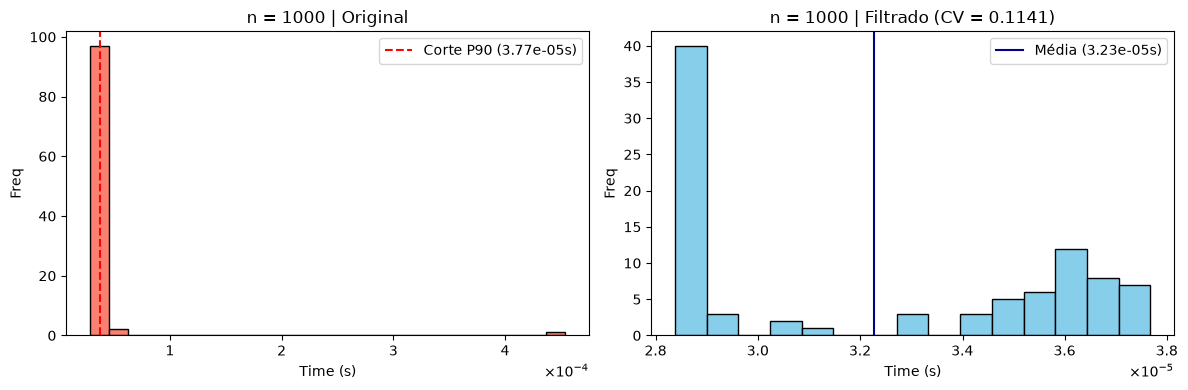

Before values
mean value: 0.0003071737289428711
standard_deviation: 1.9592199021778433e-05
coef_var: 0.06378214403036477

--------------------------------------------------------------------------------
After values
mean value: 0.0003020339541965061
standard_deviation: 9.890305768993777e-06
coef_var: 0.03274567521822084
--------------------------------------------------------------------------------


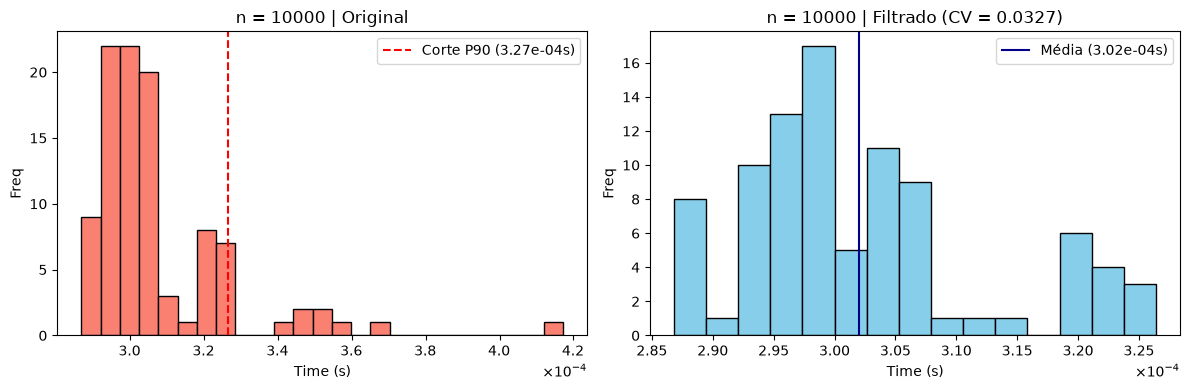

Before values
mean value: 0.0030448031425476074
standard_deviation: 0.00010290366864571353
coef_var: 0.03379649318136651

--------------------------------------------------------------------------------
After values
mean value: 0.0030164480209350585
standard_deviation: 4.7838239502402236e-05
coef_var: 0.015859129403321535
--------------------------------------------------------------------------------


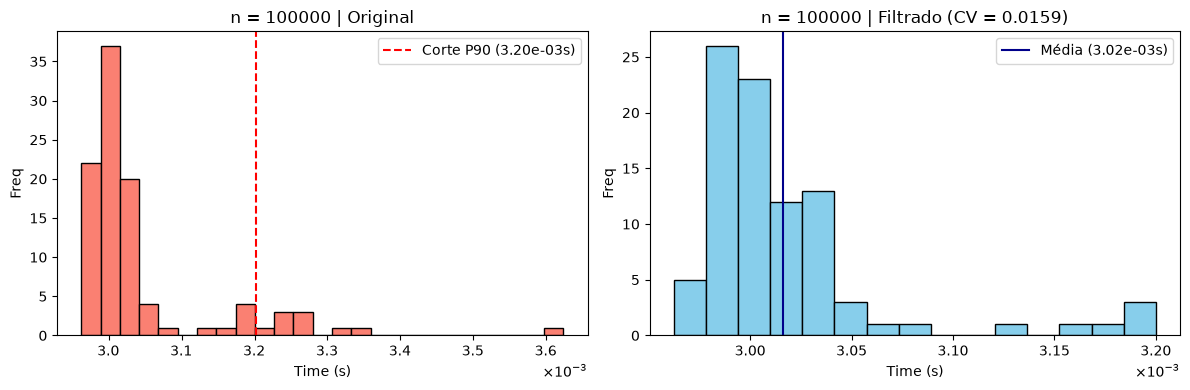

In [3]:
from time import time
from matplotlib import pyplot as plt
import numpy as np

lista_n = [1000, 10000, 100000]
l = []
R = 100

for n in lista_n:
    tic = time()
    ll = []
    for i in range(R):
        tic = time()
        for i in range(n):
            if 1 == 1:
                True
        tac = time()
        ll.append(tac - tic)

    l.append(ll)

    before_array = np.array(ll)
    mean_before = np.mean(before_array)
    bfr_std_variation = np.std(before_array)
    bfr_coef_var = bfr_std_variation / mean_before

    aft_array = np.array(ll)
    l_corte = np.percentile(aft_array, 90)
    ll_filtrado = aft_array[aft_array < l_corte]

    mean_after = np.mean(ll_filtrado)
    aft_std_variation = np.std(ll_filtrado)
    aft_coef_var = aft_std_variation / mean_after

    print(f"Before values\nmean value: {mean_before}\nstandard_deviation: {bfr_std_variation}\ncoef_var: {bfr_coef_var}\n")
    print("--"*40)
    print(f"After values\nmean value: {mean_after}\nstandard_deviation: {aft_std_variation}\ncoef_var: {aft_coef_var}")
    print("--"*40)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    #cria um histograma com ciclos dos 3 valores na lista_n
    # plt.hist(ll,25)
    #elevo os valores de x a -4 so pra facilitar a visualizacao
    # plt.ticklabel_format(axis='x', style='sci', scilimits=(0, 0), useMathText=True)
    # plt.show()
    axes[0].hist(before_array, bins=25, edgecolor='black', color='salmon')
    axes[0].axvline(l_corte, color='red', linestyle='--', label=f'Corte P90 ({l_corte:.2e}s)')
    axes[0].set_title(f"n = {n} | Original")
    axes[0].set_xlabel("Time (s)")
    axes[0].set_ylabel("Freq")
    axes[0].ticklabel_format(axis='x', style='sci', scilimits=(0, 0), useMathText=True)
    axes[0].legend()

    axes[1].hist(ll_filtrado, bins=15, edgecolor='black', color='skyblue')
    axes[1].axvline(mean_after, color='darkblue', linestyle='-', label=f'Média ({mean_after:.2e}s)')
    axes[1].set_title(f"n = {n} | Filtrado (CV = {aft_coef_var:.4f})")
    axes[1].set_xlabel("Time (s)")
    axes[1].set_ylabel("Freq")
    axes[1].ticklabel_format(axis='x', style='sci', scilimits=(0, 0), useMathText=True)
    axes[1].legend()    

    plt.tight_layout()
    plt.show()